# Занятие 7. Лабораторная работа 2. Сегментация текста на сцене (Keras)
## Нейросетевые методы обработки изображений

В этом ноутбуке мы:
1. Загрузим подвыборку набора данных Total-Text (фотографии сцен с текстом) вместе с готовыми бинарными масками областей текста.
2. Подготовим пары «изображение — маска» для обучения.
3. Реализуем архитектуру U-Net средствами библиотеки Keras (TensorFlow).
4. Обучим модель на задаче «текст / фон».
5. Сравним удобство работы с Keras и PyTorch (по опыту предыдущих занятий).

**Набор данных:** Total-Text
https://github.com/cs-chan/Total-Text-Dataset

**Важно:** все примеры рассчитаны на выполнение без графического процессора (GPU).
Используется подвыборка из 100 изображений (обучение) и 25 изображений (проверка).

---
## Шаг 1. Импорт библиотек и настройка окружения

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageDraw

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Отключаем использование графического процессора -- задача выполняется на центральном процессоре
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

print(f'TensorFlow: {tf.__version__}')
print(f'Keras: {keras.__version__}')
print(f'Доступные устройства: {tf.config.list_physical_devices()}')

TensorFlow: 2.21.0
Keras: 3.15.0
Доступные устройства: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


---
## Шаг 2. Загрузка набора данных Total-Text

### Об этом наборе

Total-Text содержит 1555 фотографий сцен с текстом: 1255 в обучающей части (Train) и 300 в тестовой (Test). Текст в кадре бывает горизонтальным, ориентированным под углом и изогнутым. Для сегментации используются готовые попиксельные бинарные маски областей текста (`Text Region Mask`): значение 1 соответствует тексту, 0 — фону. Строить маски самим не требуется.

### Инструкция по получению данных

1. Откройте страницу набора данных: https://github.com/cs-chan/Total-Text-Dataset
2. Нажмите Code → Download ZIP и распакуйте архив. В нём находятся только описания и скрипты, сами данные размещены по внешним ссылкам.
3. Ссылки на архивы указаны в файлах репозитория:
   - изображения: `Dataset/README.md`;

In [7]:
from pathlib import Path
from collections import Counter
root = Path('./data/total_text')
files = [p for p in root.rglob('*') if p.is_file()]
print(Counter(p.suffix.lower() for p in files))
for p in files[:5] + [f for f in files if 'pixel' in str(f).lower()][:5]:
    print(p)
print([str(d.relative_to(root)) for d in root.rglob('*') if d.is_dir()][:20])

Counter({'.png': 1555, '.jpg': 1555, '': 1})
data\total_text\Text_Region_Mask\.dropbox
data\total_text\Text_Region_Mask\Test\img1.png
data\total_text\Text_Region_Mask\Test\img10.png
data\total_text\Text_Region_Mask\Test\img100.png
data\total_text\Text_Region_Mask\Test\img1000.png
['Images', 'Text_Region_Mask', 'Images\\Test', 'Images\\Train', 'Text_Region_Mask\\Test', 'Text_Region_Mask\\Train']


In [8]:
from pathlib import Path

DATA_DIR = Path('./data/total_text')
IMG_DIR = DATA_DIR / 'Images'
MASK_DIR = DATA_DIR / 'Text_Region_Mask'

def list_pairs(split):
    pairs = []
    for img in sorted((IMG_DIR / split).glob('*.jpg')):
        if img.name.startswith('._'):
            continue
        msk = MASK_DIR / split / f'{img.stem}.png'
        if msk.exists():
            pairs.append((img, msk))
    return pairs

train_pairs, test_pairs = list_pairs('Train'), list_pairs('Test')
print(f'Пар в Train: {len(train_pairs)}, в Test: {len(test_pairs)}')

Пар в Train: 1255, в Test: 300


---
## Шаг 3. Загрузка бинарной маски текста

В наборе Total-Text разметка уже представлена в виде попиксельных масок областей текста (файлы `Text_Region_Mask/.../img*.png`), поэтому строить маски из координат контуров не требуется. Задача этого шага — привести готовую маску к виду, пригодному для обучения сети.

Функция `load_text_mask` выполняет три действия:
1. Открывает PNG-файл маски и переводит его в одноканальное изображение в градациях серого.
2. Уменьшает маску до размера `IMG_SIZE × IMG_SIZE` методом ближайшего соседа (`Image.NEAREST`). Интерполяция другого типа создала бы промежуточные значения серого на границах букв, а маска должна содержать только значения 0 и 1.
3. Бинаризует результат по порогу 127. В исходных масках текст отображён белым цветом (значение 255), фон — чёрным (значение 0). После бинаризации пикселям текста присваивается значение 1, фону — значение 0.

Размер маски должен совпадать с размером изображения, которое уменьшается в Шаге 4 до тех же `IMG_SIZE × IMG_SIZE`.

In [9]:
def load_text_mask(mask_path, size):
    mask = Image.open(mask_path).convert('L').resize((size, size), Image.NEAREST)
    return (np.array(mask) > 127).astype(np.float32)

print('Функция load_text_mask определена.')

Функция load_text_mask определена.


---
## Шаг 4. Формирование подвыборки пар (изображение, маска)

Без графического процессора обучение на всех 1555 изображениях заняло бы слишком много времени, поэтому используем компактную подвыборку: `TRAIN_SIZE` изображений из обучающей части набора (Train) для обучения и `VAL_SIZE` изображений из тестовой части (Test) для проверки. Значения этих параметров задаются в ячейке ниже.

Для каждой пары выполняются два действия:
1. Изображение переводится в формат RGB, уменьшается до `IMG_SIZE × IMG_SIZE` и нормируется в диапазон [0, 1].
2. Маска загружается функцией `load_text_mask` из Шага 3 и получает дополнительную ось канала: форма `(IMG_SIZE, IMG_SIZE, 1)`.

Пары выбираются случайно с фиксированным значением `SEED`, поэтому подвыборка воспроизводима. Итоговые массивы: `X_train`, `y_train`, `X_val`, `y_val`. Последняя строка вывода показывает долю пикселей текста (около 9% в нашей подвыборке) и подтверждает, что маски содержат только значения 0 и 1.

In [25]:
IMG_SIZE = 128
TRAIN_SIZE, VAL_SIZE = 150, 30

def build_dataset_arrays(pairs, img_size=IMG_SIZE):
    images, masks = [], []
    for img_path, msk_path in pairs:
        image = Image.open(img_path).convert('RGB').resize((img_size, img_size), Image.BILINEAR)
        images.append(np.array(image, dtype=np.float32) / 255.0)
        masks.append(load_text_mask(msk_path, img_size)[..., np.newaxis])
    return np.array(images), np.array(masks)

rng = np.random.default_rng(SEED)
train_sel = [train_pairs[i] for i in rng.permutation(len(train_pairs))[:TRAIN_SIZE]]
val_sel = [test_pairs[i] for i in rng.permutation(len(test_pairs))[:VAL_SIZE]]

X_train, y_train = build_dataset_arrays(train_sel)
X_val, y_val = build_dataset_arrays(val_sel)
print(f'Обучающая подвыборка: {X_train.shape}, маски: {y_train.shape}')
print(f'Проверочная подвыборка: {X_val.shape}, маски: {y_val.shape}')
print(f'Доля текста: {y_train.mean():.2%}; значения масок: {np.unique(y_train)}')

Обучающая подвыборка: (150, 128, 128, 3), маски: (150, 128, 128, 1)
Проверочная подвыборка: (30, 128, 128, 3), маски: (30, 128, 128, 1)
Доля текста: 8.73%; значения масок: [0. 1.]


---
## Шаг 5. Визуализация примеров: изображение и маска текста

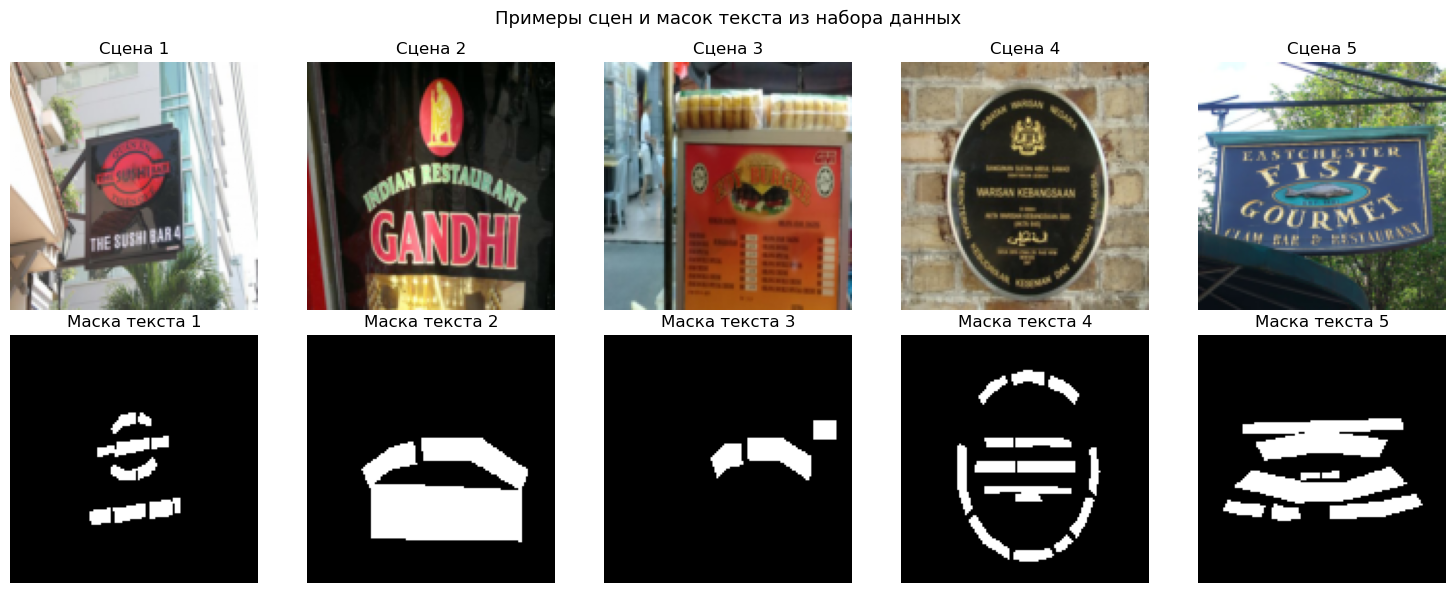

Средняя доля пикселей текста от общей площади изображения: 8.73%
(иллюстрирует выраженный дисбаланс классов, описанный в теории)


In [26]:
if X_train is not None and len(X_train) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for i in range(5):
        axes[0, i].imshow(X_train[i])
        axes[0, i].set_title(f'Сцена {i+1}')
        axes[0, i].axis('off')
        axes[1, i].imshow(y_train[i, :, :, 0], cmap='gray')
        axes[1, i].set_title(f'Маска текста {i+1}')
        axes[1, i].axis('off')
    plt.suptitle('Примеры сцен и масок текста из набора данных', fontsize=13)
    plt.tight_layout()
    plt.show()

    text_ratio = y_train.mean()
    print(f'Средняя доля пикселей текста от общей площади изображения: {text_ratio:.2%}')
    print('(иллюстрирует выраженный дисбаланс классов, описанный в теории)')

Маски грубые: это закрашенные области вокруг слов, а не контуры букв. На сцене 2 слово «GANDHI» перекрыто широкой коробкой, на сцене 3 размечены только отдельные фрагменты меню, часть текста остаётся без маски. Для лабораторной это допустимо, но Dice и IoU на проверке будут ограничены сверху такой разметкой.

---
## Шаг 6. Архитектура U-Net на Keras

Обратите внимание на компактность определения архитектуры по сравнению
с реализацией на PyTorch: слои соединяются напрямую
через функциональный интерфейс Keras.

In [27]:
def double_conv_block(x, n_filters):
    """Два последовательных свёрточных слоя 3x3 с нормализацией и функцией активации ReLU."""
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x


def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=16):
    inputs = keras.Input(shape=input_shape)

    # Сжимающий путь
    e1 = double_conv_block(inputs, base_filters)
    p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv_block(p1, base_filters * 2)
    p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv_block(p2, base_filters * 4)
    p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv_block(p3, base_filters * 8)

    # Расширяющий путь с соединениями быстрого доступа
    u3 = layers.Conv2DTranspose(base_filters * 4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3])
    d3 = double_conv_block(u3, base_filters * 4)

    u2 = layers.Conv2DTranspose(base_filters * 2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2])
    d2 = double_conv_block(u2, base_filters * 2)

    u1 = layers.Conv2DTranspose(base_filters, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1])
    d1 = double_conv_block(u1, base_filters)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(d1)

    return keras.Model(inputs, outputs, name='LightUNet_Keras')


model = build_unet()
model.summary()

Model: "LightUNet_Keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_30 (Conv2D)            │ (None, 128, 128, 16)      │             448 │ input_layer_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_28        │ (None, 128, 128, 16)      │              64 │ conv2d_30[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_28 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_28[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_31 (Conv2D)            │ (None, 128, 128, 16)      │           2,320 │ activation_28[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_29        │ (None, 128, 128, 16)      │              64 │ conv2d_31[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_29 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_29[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_6               │ (None, 64, 64, 16)        │               0 │ activation_29[0][0]        │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_32 (Conv2D)            │ (None, 64, 64, 32)        │           4,640 │ max_pooling2d_6[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_30        │ (None, 64, 64, 32)        │             128 │ conv2d_32[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_30 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_30[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_33 (Conv2D)            │ (None, 64, 64, 32)        │           9,248 │ activation_30[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_31        │ (None, 64, 64, 32)        │             128 │ conv2d_33[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_31 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_31[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_7               │ (None, 32, 32, 32)        │               

 Total params: 484,849 (1.85 MB)

 Trainable params: 483,441 (1.84 MB)

 Non-trainable params: 1,408 (5.50 KB)

---
## Шаг 7. Функция потерь и метрики (коэффициент Дайса, IoU)

Вследствие выраженного дисбаланса классов (текст занимает малую долю площади
кадра) используем комбинированную функцию потерь: бинарная кросс-энтропия
+ функция потерь Дайса.

In [28]:
def dice_coefficient_metric(y_true, y_pred, epsilon=1e-6):
    y_pred_binary = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred_binary, axis=[1, 2, 3])
    union_sum = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred_binary, axis=[1, 2, 3])
    return tf.reduce_mean((2.0 * intersection + epsilon) / (union_sum + epsilon))


def iou_metric(y_true, y_pred, epsilon=1e-6):
    y_pred_binary = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred_binary, axis=[1, 2, 3])
    union = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred_binary, axis=[1, 2, 3]) - intersection
    return tf.reduce_mean((intersection + epsilon) / (union + epsilon))


def dice_loss(y_true, y_pred, epsilon=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    union_sum = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return 1.0 - tf.reduce_mean((2.0 * intersection + epsilon) / (union_sum + epsilon))


def combined_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=[dice_coefficient_metric, iou_metric]
)

print('Модель скомпилирована: оптимизатор Adam, комбинированная функция потерь.')
print('Обратите внимание: во всём цикле обучения ниже -- одна команда model.fit(),')
print('в отличие от явного цикла по эпохам и пакетам данных, написанного вручную на PyTorch.')

Модель скомпилирована: оптимизатор Adam, комбинированная функция потерь.
Обратите внимание: во всём цикле обучения ниже -- одна команда model.fit(),
в отличие от явного цикла по эпохам и пакетам данных, написанного вручную на PyTorch.


---
## Шаг 8. Обучение модели

Весь цикл обучения (проход вперёд, вычисление потерь, обратное распространение
ошибки, шаг оптимизации, проверка на валидационной выборке) выполняется
внутри одной команды `model.fit()`.

In [29]:
import time

if X_train is not None and len(X_train) > 0:
    NUM_EPOCHS = 15
    t_start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=NUM_EPOCHS,
        batch_size=8,
        verbose=1
    )

    print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')
    print(f'Строк кода для полного цикла обучения: 1 (метод model.fit)')

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - dice_coefficient_metric: 0.1734 - iou_metric: 0.1009 - loss: 1.7492 - val_dice_coefficient_metric: 0.0338 - val_iou_metric: 0.0176 - val_loss: 1.4654
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 191ms/step - dice_coefficient_metric: 0.2323 - iou_metric: 0.1437 - loss: 1.4766 - val_dice_coefficient_metric: 0.0043 - val_iou_metric: 0.0021 - val_loss: 1.4184
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - dice_coefficient_metric: 0.2879 - iou_metric: 0.1911 - loss: 1.4019 - val_dice_coefficient_metric: 0.0049 - val_iou_metric: 0.0025 - val_loss: 1.4449
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 197ms/step - dice_coefficient_metric: 0.3393 - iou_metric: 0.2380 - loss: 1.3425 - val_dice_coefficient_metric: 0.0834 - val_iou_metric: 0.0472 - val_loss: 1.4823
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - dice_coefficient_metric: 0.3972 - iou_metric: 0.2836 - loss: 1.2827 - val_dice_coefficient_metric: 0.0706 - val_iou_metric: 0.041

---
## Шаг 9. Визуализация кривых обучения

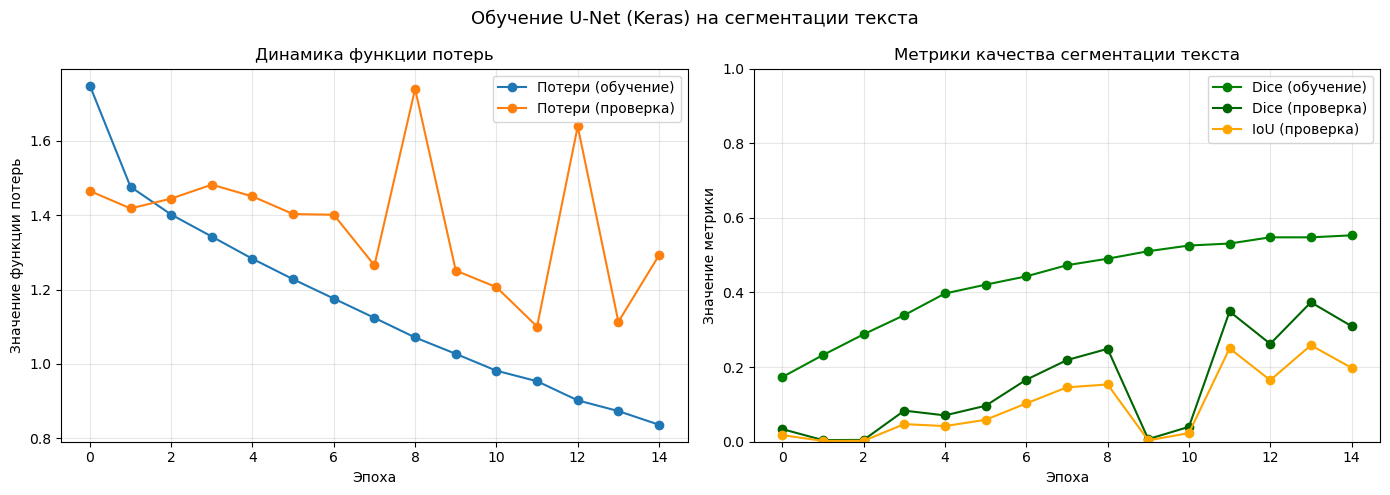

Итоговый Dice на проверочной выборке: 0.3097
Итоговый IoU на проверочной выборке:  0.1980


In [30]:
if X_train is not None and len(X_train) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(history.history['val_loss'], label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['dice_coefficient_metric'], label='Dice (обучение)', marker='o', color='green')
    axes[1].plot(history.history['val_dice_coefficient_metric'], label='Dice (проверка)', marker='o', color='darkgreen')
    axes[1].plot(history.history['val_iou_metric'], label='IoU (проверка)', marker='o', color='orange')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Значение метрики')
    axes[1].set_title('Метрики качества сегментации текста'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение U-Net (Keras) на сегментации текста', fontsize=13)
    plt.tight_layout()
    plt.show()

    final_dice = history.history['val_dice_coefficient_metric'][-1]
    final_iou  = history.history['val_iou_metric'][-1]
    print(f'Итоговый Dice на проверочной выборке: {final_dice:.4f}')
    print(f'Итоговый IoU на проверочной выборке:  {final_iou:.4f}')

---
## Шаг 10. Визуальное сравнение эталонной маски и предсказания модели

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step


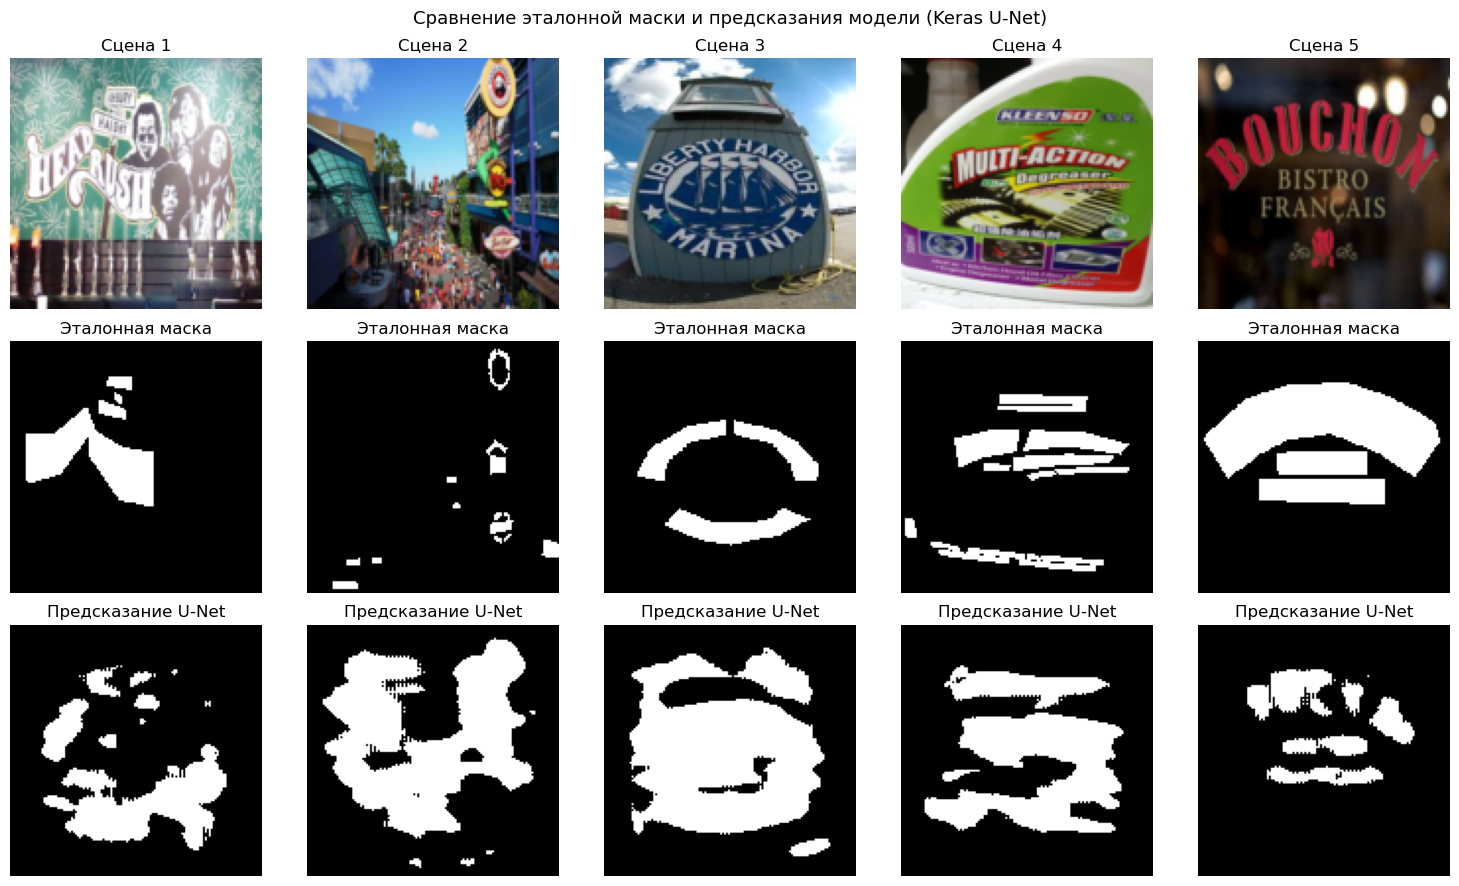

In [31]:
if X_train is not None and len(X_train) > 0:
    predictions = model.predict(X_val[:5])

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    for i in range(5):
        axes[0, i].imshow(X_val[i]); axes[0, i].set_title(f'Сцена {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(y_val[i, :, :, 0], cmap='gray'); axes[1, i].set_title('Эталонная маска'); axes[1, i].axis('off')
        pred_binary = (predictions[i, :, :, 0] > 0.5).astype(np.float32)
        axes[2, i].imshow(pred_binary, cmap='gray'); axes[2, i].set_title('Предсказание U-Net'); axes[2, i].axis('off')

    plt.suptitle('Сравнение эталонной маски и предсказания модели (Keras U-Net)', fontsize=13)
    plt.tight_layout()
    plt.show()

In [32]:
pred_tr = model.predict(X_train[:25], verbose=0)
pred_va = model.predict(X_val, verbose=0)
pred_va_bn = model(X_val, training=True).numpy()

def stats(name, p, y):
    pb = (p > 0.5).astype(np.float32)
    dice = (2 * (y * pb).sum() + 1e-6) / (y.sum() + pb.sum() + 1e-6)
    print(f'{name}: max={p.max():.3f} mean={p.mean():.3f} доля>0.5={pb.mean():.2%} Dice={dice:.4f}')

stats('train (inference)', pred_tr, y_train[:25])
stats('val   (inference)', pred_va, y_val)
stats('val   (training=True)', pred_va_bn, y_val)
print('Потери по эпохам:', [round(v, 3) for v in history.history['loss']])
print('Dice train по эпохам:', [round(v, 3) for v in history.history['dice_coefficient_metric']])

train (inference): max=1.000 mean=0.373 доля>0.5=31.24% Dice=0.4283
val   (inference): max=1.000 mean=0.360 доля>0.5=28.99% Dice=0.3469
val   (training=True): max=1.000 mean=0.172 доля>0.5=10.04% Dice=0.5646
Потери по эпохам: [1.749, 1.477, 1.402, 1.343, 1.283, 1.228, 1.176, 1.124, 1.071, 1.027, 0.982, 0.953, 0.902, 0.873, 0.836]
Dice train по эпохам: [0.173, 0.232, 0.288, 0.339, 0.397, 0.421, 0.443, 0.473, 0.49, 0.511, 0.526, 0.531, 0.548, 0.548, 0.553]


### Перепишем!

In [33]:
def double_conv_block(x, n_filters):
    """Два последовательных свёрточных слоя 3x3 с нормализацией и функцией активации ReLU."""
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    return x


def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=16):
    inputs = keras.Input(shape=input_shape)

    # Сжимающий путь
    e1 = double_conv_block(inputs, base_filters)
    p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv_block(p1, base_filters * 2)
    p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv_block(p2, base_filters * 4)
    p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv_block(p3, base_filters * 8)

    # Расширяющий путь с соединениями быстрого доступа
    u3 = layers.Conv2DTranspose(base_filters * 4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3])
    d3 = double_conv_block(u3, base_filters * 4)

    u2 = layers.Conv2DTranspose(base_filters * 2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2])
    d2 = double_conv_block(u2, base_filters * 2)

    u1 = layers.Conv2DTranspose(base_filters, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1])
    d1 = double_conv_block(u1, base_filters)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(d1)

    return keras.Model(inputs, outputs, name='LightUNet_Keras')


model = build_unet()
model.summary()

Model: "LightUNet_Keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_45 (Conv2D)            │ (None, 128, 128, 16)      │             448 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_42        │ (None, 128, 128, 16)      │              64 │ conv2d_45[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_42 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_42[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_46 (Conv2D)            │ (None, 128, 128, 16)      │           2,320 │ activation_42[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_43        │ (None, 128, 128, 16)      │              64 │ conv2d_46[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_43 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_43[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_9               │ (None, 64, 64, 16)        │               0 │ activation_43[0][0]        │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_47 (Conv2D)            │ (None, 64, 64, 32)        │           4,640 │ max_pooling2d_9[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_44        │ (None, 64, 64, 32)        │             128 │ conv2d_47[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_44 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_44[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_48 (Conv2D)            │ (None, 64, 64, 32)        │           9,248 │ activation_44[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_45        │ (None, 64, 64, 32)        │             128 │ conv2d_48[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_45 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_45[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_10              │ (None, 32, 32, 32)        │               

 Total params: 484,849 (1.85 MB)

 Trainable params: 483,441 (1.84 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [34]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-3),
    loss=combined_loss,
    metrics=[dice_coefficient_metric, iou_metric]
)

In [35]:
import time

if X_train is not None and len(X_train) > 0:
    NUM_EPOCHS = 30
    t_start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=NUM_EPOCHS,
        batch_size=16,
        verbose=1
    )

    print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')
    print(f'Строк кода для полного цикла обучения: 1 (метод model.fit)')

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 465ms/step - dice_coefficient_metric: 0.2048 - iou_metric: 0.1247 - loss: 1.6344 - val_dice_coefficient_metric: 0.0382 - val_iou_metric: 0.0205 - val_loss: 1.5095
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 407ms/step - dice_coefficient_metric: 0.2010 - iou_metric: 0.1347 - loss: 1.3306 - val_dice_coefficient_metric: 0.0343 - val_iou_metric: 0.0193 - val_loss: 1.3373
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 395ms/step - dice_coefficient_metric: 0.2064 - iou_metric: 0.1402 - loss: 1.2299 - val_dice_coefficient_metric: 0.2097 - val_iou_metric: 0.1427 - val_loss: 1.2197
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 390ms/step - dice_coefficient_metric: 0.3153 - iou_metric: 0.2216 - loss: 1.1282 - val_dice_coefficient_metric: 0.2258 - val_iou_metric: 0.1572 - val_loss: 1.1748
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 396ms/step - dice_coefficient_metric: 0.3494 - iou_metric: 0.2510 - loss: 1.0519 - val_dice_coefficient_metric: 0.2478 - val_iou_metric: 0.172

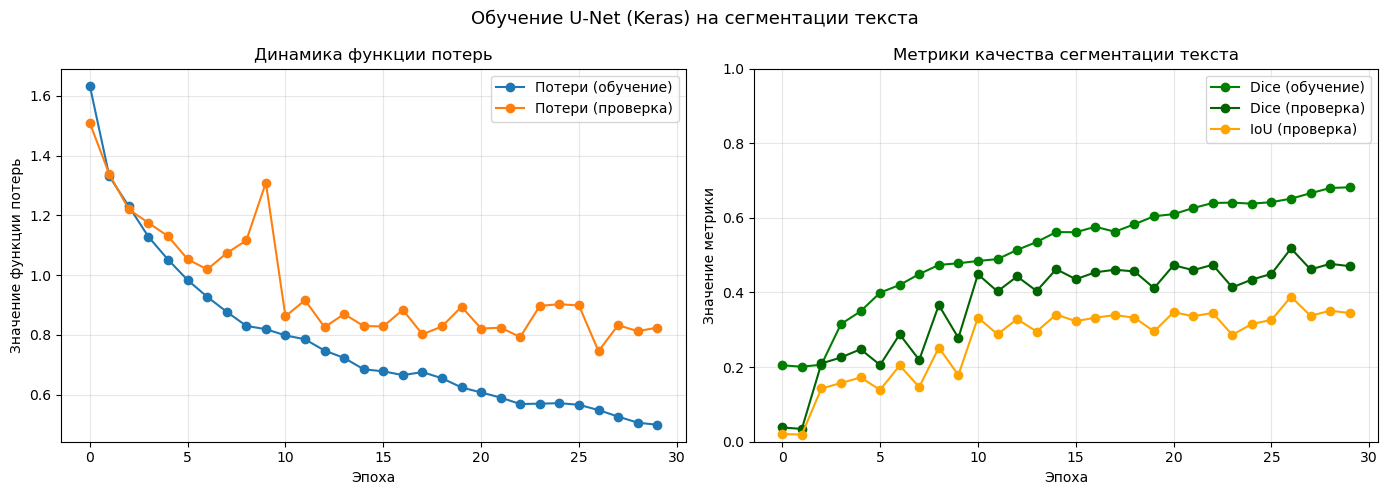

Итоговый Dice на проверочной выборке: 0.4705
Итоговый IoU на проверочной выборке:  0.3448


In [36]:
if X_train is not None and len(X_train) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(history.history['val_loss'], label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['dice_coefficient_metric'], label='Dice (обучение)', marker='o', color='green')
    axes[1].plot(history.history['val_dice_coefficient_metric'], label='Dice (проверка)', marker='o', color='darkgreen')
    axes[1].plot(history.history['val_iou_metric'], label='IoU (проверка)', marker='o', color='orange')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Значение метрики')
    axes[1].set_title('Метрики качества сегментации текста'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение U-Net (Keras) на сегментации текста', fontsize=13)
    plt.tight_layout()
    plt.show()

    final_dice = history.history['val_dice_coefficient_metric'][-1]
    final_iou  = history.history['val_iou_metric'][-1]
    print(f'Итоговый Dice на проверочной выборке: {final_dice:.4f}')
    print(f'Итоговый IoU на проверочной выборке:  {final_iou:.4f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step


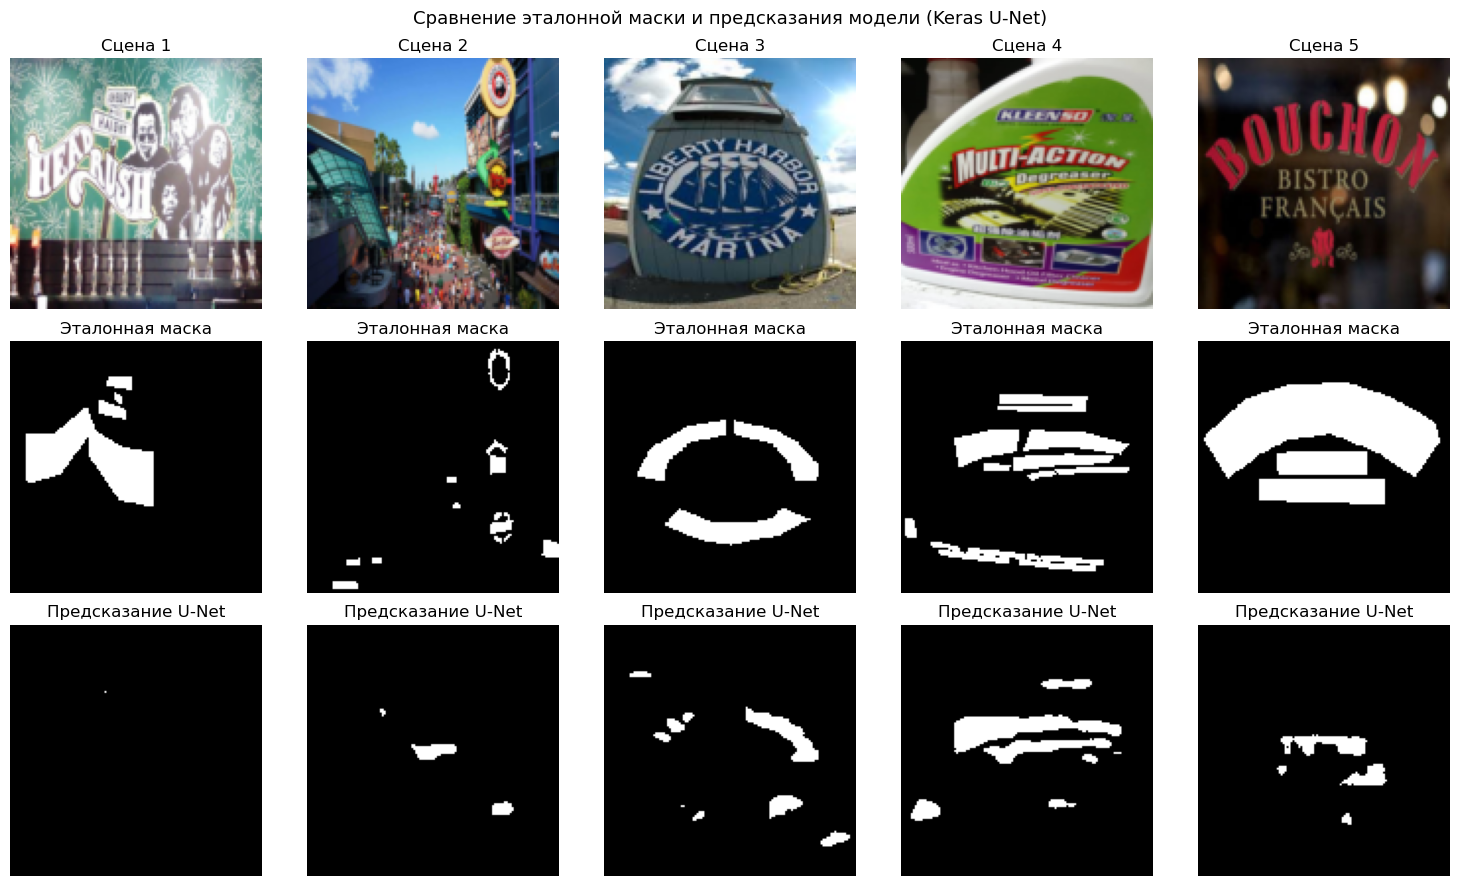

In [37]:
if X_train is not None and len(X_train) > 0:
    predictions = model.predict(X_val[:5])

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    for i in range(5):
        axes[0, i].imshow(X_val[i]); axes[0, i].set_title(f'Сцена {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(y_val[i, :, :, 0], cmap='gray'); axes[1, i].set_title('Эталонная маска'); axes[1, i].axis('off')
        pred_binary = (predictions[i, :, :, 0] > 0.5).astype(np.float32)
        axes[2, i].imshow(pred_binary, cmap='gray'); axes[2, i].set_title('Предсказание U-Net'); axes[2, i].axis('off')

    plt.suptitle('Сравнение эталонной маски и предсказания модели (Keras U-Net)', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 11. Мини-опрос и обсуждение: Keras против PyTorch

Сравнение опыта разработки на основании выполненных лабораторных работ
(занятие 5-6 -- PyTorch, занятие 7 -- Keras).

In [24]:
comparison_table = {
    'Критерий': [
        'Число строк кода для определения архитектуры U-Net',
        'Число строк кода для полного цикла обучения',
        'Необходимость явного вызова backward() и optimizer.step()',
        'Автоматическое ведение истории обучения (loss, метрики)',
        'Простота встраивания собственной метрики',
        'Прозрачность промежуточных вычислений для отладки',
    ],
    'PyTorch (занятие 5-6)': [
        '~25 строк (класс с методом forward)',
        '~20-25 строк (явный цикл по эпохам и пакетам)',
        'Да, требуется',
        'Нет, реализуется вручную (список history)',
        'Требуется отдельная функция + ручной вызов',
        'Высокая (каждый шаг виден в коде)',
    ],
    'Keras (занятие 7)': [
        '~20 строк (функциональный API)',
        '1 строка (model.fit)',
        'Нет, скрыто внутри fit()',
        'Да, встроено (объект history)',
        'Передаётся в compile(metrics=[...])',
        'Ниже (внутренние шаги скрыты библиотекой)',
    ]
}

import pandas as pd
df_comparison = pd.DataFrame(comparison_table)
print(df_comparison.to_string(index=False))
print()
print('Вопросы для обсуждения на занятии:')
print('1. В каком из двух подходов было легче найти и исправить ошибку в вычислении метрики?')
print('2. Какой из фреймворков дал более быстрое понимание происходящего внутри цикла обучения?')
print('3. Какой подход предпочтителен для быстрого прототипирования, а какой -- для')
print('   тонкой настройки нестандартной схемы обучения?')

                                                 Критерий                         PyTorch (занятие 5-6)                         Keras (занятие 7)
       Число строк кода для определения архитектуры U-Net           ~25 строк (класс с методом forward)            ~20 строк (функциональный API)
              Число строк кода для полного цикла обучения ~20-25 строк (явный цикл по эпохам и пакетам)                      1 строка (model.fit)
Необходимость явного вызова backward() и optimizer.step()                                 Да, требуется                  Нет, скрыто внутри fit()
  Автоматическое ведение истории обучения (loss, метрики)     Нет, реализуется вручную (список history)             Да, встроено (объект history)
                 Простота встраивания собственной метрики    Требуется отдельная функция + ручной вызов       Передаётся в compile(metrics=[...])
        Прозрачность промежуточных вычислений для отладки             Высокая (каждый шаг виден в коде) Ниже (внутренние шаг

---
## Итоговая сводка

| Компонент | Реализация в ноутбуке |
|---|---|
| Набор данных | Total-Text: фотографии сцен с горизонтальным, ориентированным и изогнутым текстом; подвыборка `TRAIN_SIZE` изображений из Train и `VAL_SIZE` из Test |
| Разметка | Готовые бинарные маски областей текста (`Text_Region_Mask`, PNG): текст — 1, фон — 0 |
| Предобработка | Приведение изображений и масок к размеру `IMG_SIZE × IMG_SIZE`, нормировка изображений в диапазон [0, 1] |
| Библиотека | Keras (TensorFlow), выполнение на центральном процессоре |
| Архитектура | U-Net, функциональный API, базовое число каналов 16, `BatchNormalization(momentum=0.9)` |
| Функция потерь | Сумма бинарной кросс-энтропии и функции потерь Дайса |
| Метрики | Коэффициент Дайса и IoU (пользовательские функции Keras) |
| Сопоставление фреймворков | Таблица различий Keras и PyTorch по итогам двух лабораторных работ |

**Что показала работа.** Текст занимает небольшую долю пикселей, поэтому используется комбинированная функция потерь. Метрики на проверке всегда считаются в режиме предсказания (`training=False`). Если они близки к нулю при хорошем качестве на обучении, причина может быть в статистиках слоёв нормализации (см. задание 4).

---
## Домашнее задание

1. **Основное.** Реализуйте ту же архитектуру U-Net на Keras с использованием класса `keras.Model` через наследование (объектно-ориентированный подход, переопределение метода `call()`), а не функциональный API, использованный в ноутбуке. Убедитесь, что при том же `SEED` и числе эпох метрики Dice и IoU сопоставимы с результатом из ноутбука. Сравните читаемость получившегося кода с функциональным подходом.

2. **Эксперимент с балансировкой классов.** Постройте вариант функции потерь с явным весовым коэффициентом для класса «текст» (например, весовая бинарная кросс-энтропия с весом 5–10 для текстовых пикселей). Сравните значения Dice и IoU на проверочной выборке с результатом комбинированной функции потерь из ноутбука. Объясните, как выбранный вес связан с долей пикселей текста, полученной в Шаге 4.

3. **Анализ ошибок по изображениям.** Для каждого изображения проверочной выборки отдельно посчитайте Dice и долю пикселей текста в эталонной маске. Разделите изображения на две группы по медиане этой доли и сравните средний Dice групп. Постройте диаграмму рассеяния «доля текста — Dice». Объясните причины различий, опираясь на примеры из Шагов 5 и 10 (мелкие надписи, изогнутый текст, неполная разметка).

4. **(Дополнительно)** Исследуйте влияние параметра `momentum` слоя `BatchNormalization`. Обучите модели со значениями 0.99 (по умолчанию) и 0.9. Для каждой посчитайте Dice на проверочной выборке в режиме `training=False` и по батчевой статистике (`model(X_val, training=True)`). Объясните, почему при малом числе шагов обучения результаты в двух режимах расходятся.

5. **(Дополнительно)** Составьте письменный отчёт на одну страницу по итогам мини-опроса из Шага 11: сформулируйте собственную позицию, какой из двух фреймворков вы предпочли бы использовать для а) учебного проекта, б) исследовательской работы с нестандартной архитектурой, и обоснуйте выбор. Приведите хотя бы один пример из выполненных лабораторных работ.

In [1]:
from pathlib import Path
p = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text\Text_Region_Mask\Train')
txts = sorted(p.glob('*.txt'))
print('Всего .txt:', len(txts))
print('\nПервые 3 файла и их содержимое (первые 200 символов):\n')
for t in txts[:3]:
    print('=' * 60)
    print(t.name, '—', t.stat().st_size, 'байт')
    print(repr(t.read_text(encoding='utf-8', errors='ignore')[:200]))

Всего .txt: 1255

Первые 3 файла и их содержимое (первые 200 символов):

poly_gt_img1001.txt — 849 байт
"x: [[153 161 179 195 184 177]], y: [[347 323 305 315 331 357]], ornt: [u'c'], transcriptions: [u'the']\nx: [[184 222 273 269 230 202]], y: [[293 269 270 296 297 317]], ornt: [u'c'], transcriptions: [u'"
poly_gt_img1002.txt — 1181 байт
"x: [[125 198 270 270 198 125]], y: [[355 355 355 374 374 374]], ornt: [u'h'], transcriptions: [u'CONSTRUCTIONS']\nx: [[ 77 119 161 161 119  77]], y: [[442 442 442 468 468 468]], ornt: [u'h'], transcrip"
poly_gt_img1003.txt — 561 байт
"x: [[606 622 637 637 622 606]], y: [[181 181 181 201 201 201]], ornt: [u'h'], transcriptions: [u'FUEL']\nx: [[496 598 720 736 621 502]], y: [[508 493 467 521 560 592]], ornt: [u'c'], transcriptions: [u"


In [3]:
"""
Генерация PNG-масок из poly_gt_*.txt (формат Total-Text).
Файлы .txt содержат строки вида:
  x: [[153 161 179 195 184 177]], y: [[347 323 305 315 331 357]], ornt: [...], transcriptions: [...]
Каждая строка — один полигон. Пары x[i], y[i] — точки.
"""
from pathlib import Path
from PIL import Image, ImageDraw
import re
import numpy as np

ROOT = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text')
IMG_DIR = ROOT / 'Images'
MSK_DIR = ROOT / 'Text_Region_Mask'
SIZE = 128

# x: [[1 2 3 4]]  или x:[[...]] — ловим всё, что в двойных скобках
RE_X = re.compile(r"x\s*:\s*\[\[([^\]]+)\]\]")
RE_Y = re.compile(r"y\s*:\s*\[\[([^\]]+)\]\]")


def parse_poly_gt(txt_path: Path):
    """
    Возвращает список полигонов: [[(x1,y1), (x2,y2), ...], ...]
    Формат строк в файле:
        x: [[153 161 179 195 184 177]], y: [[347 323 305 315 331 357]], ...
    """
    text = txt_path.read_text(encoding='utf-8', errors='ignore')
    polys = []
    for line in text.splitlines():
        mx = RE_X.search(line)
        my = RE_Y.search(line)
        if not mx or not my:
            continue
        xs = [float(v) for v in mx.group(1).split()]
        ys = [float(v) for v in my.group(1).split()]
        if len(xs) != len(ys) or len(xs) < 3:
            continue
        poly = list(zip(xs, ys))
        polys.append(poly)
    return polys


def make_mask(polys, size, scale):
    m = Image.new('L', (size, size), 0)
    d = ImageDraw.Draw(m)
    sx, sy = scale
    for poly in polys:
        d.polygon([(x * sx, y * sy) for x, y in poly], fill=255)
    return m


def collect_images(split: str):
    """stem -> путь к картинке. Рекурсивно."""
    result = {}
    split_dir = IMG_DIR / split
    if not split_dir.exists():
        return result
    for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG'):
        for p in split_dir.rglob(ext):
            if p.name.startswith('._'):
                continue
            result.setdefault(p.stem, p)
    return result


def generate_for_split(split: str):
    split_dir = MSK_DIR / split
    txts = [p for p in split_dir.rglob('*.txt') if not p.name.startswith('._')]
    imgs = collect_images(split)
    print(f'[gen] {split}: .txt = {len(txts)}, изображений = {len(imgs)}')

    n_saved = n_no_img = n_no_poly = 0
    for t in txts:
        # имя: poly_gt_img1001.txt -> stem = poly_gt_img1001 -> отрежем "poly_gt_"
        stem = t.stem
        if stem.startswith('poly_gt_'):
            img_stem = stem[len('poly_gt_'):]
        else:
            img_stem = stem

        img_path = imgs.get(img_stem)
        if img_path is None:
            n_no_img += 1
            continue

        with Image.open(img_path) as im:
            w, h = im.size
        sx, sy = SIZE / w, SIZE / h

        polys = parse_poly_gt(t)
        if not polys:
            n_no_poly += 1
            continue

        mask = make_mask(polys, SIZE, (sx, sy))
        out = t.with_name(f'{img_stem}.png')  # img1001.png
        mask.save(out)
        n_saved += 1

    print(f'  сохранено: {n_saved}  (без картинки: {n_no_img}, без полигонов: {n_no_poly})')
    return n_saved


if __name__ == '__main__':
    total = 0
    for split in ('Train', 'Test'):
        total += generate_for_split(split)
    print(f'\nВсего масок: {total}')

[gen] Train: .txt = 1255, изображений = 1255
  сохранено: 1255  (без картинки: 0, без полигонов: 0)
[gen] Test: .txt = 300, изображений = 300
  сохранено: 300  (без картинки: 0, без полигонов: 0)

Всего масок: 1555


маска существует: True — C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text\Text_Region_Mask\Train\img1001.png


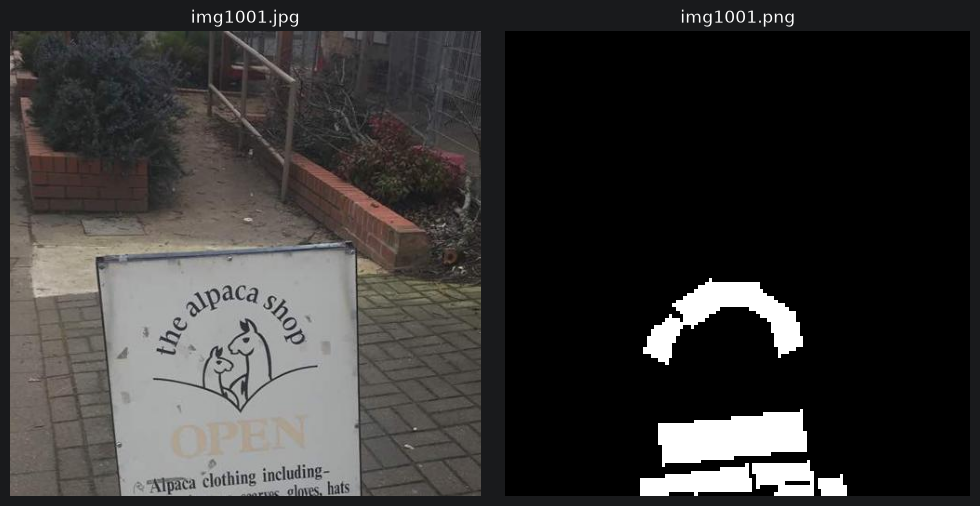

In [4]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

root = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text')
img = sorted((root / 'Images' / 'Train').glob('*.jpg'))[0]
msk = (root / 'Text_Region_Mask' / 'Train') / f'{img.stem}.png'
print('маска существует:', msk.exists(), '—', msk)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(Image.open(img)); ax[0].set_title(img.name); ax[0].axis('off')
ax[1].imshow(Image.open(msk), cmap='gray'); ax[1].set_title(msk.name); ax[1].axis('off')
plt.tight_layout(); plt.show()

C:\Users\Svetozar\PycharmProjects\NTMIP\.venv\Lib\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


Train: (150, 128, 128, 3) / Val: (30, 128, 128, 3), доля текста: 10.13%


Model: "DeepResUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │        672 │ input_layer[0][0] │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      5,208 │ activation[0][0]  │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │         96 │ input_layer[0][0] │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         96 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 24)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ add[0][0]         │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ activation_1[0][… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     10,416 │ max_pooling2d[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     20,784 │ activation_2[0][… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      1,200 │ max_pooling2d[0]

 Total params: 4,576,129 (17.46 MB)

 Trainable params: 4,569,505 (17.43 MB)

 Non-trainable params: 6,624 (25.88 KB)

Epoch 1/15
19/19 - 35s - 2s/step - dice_metric: 0.2845 - iou_metric: 0.1848 - loss: 1.2648 - val_dice_metric: 0.1902 - val_iou_metric: 0.1088 - val_loss: 18.0566
Epoch 2/15
19/19 - 7s - 381ms/step - dice_metric: 0.4035 - iou_metric: 0.2846 - loss: 0.9849 - val_dice_metric: 0.1987 - val_iou_metric: 0.1146 - val_loss: 21.0700
Epoch 3/15
19/19 - 7s - 367ms/step - dice_metric: 0.4600 - iou_metric: 0.3336 - loss: 0.8889 - val_dice_metric: 0.2091 - val_iou_metric: 0.1218 - val_loss: 11.8346
Epoch 4/15
19/19 - 7s - 378ms/step - dice_metric: 0.5042 - iou_metric: 0.3725 - loss: 0.8160 - val_dice_metric: 0.2574 - val_iou_metric: 0.1553 - val_loss: 3.9987
Epoch 5/15
19/19 - 7s - 380ms/step - dice_metric: 0.5364 - iou_metric: 0.3999 - loss: 0.7620 - val_dice_metric: 0.2781 - val_iou_metric: 0.1744 - val_loss: 2.2510
Epoch 6/15
19/19 - 7s - 374ms/step - dice_metric: 0.5594 - iou_metric: 0.4220 - loss: 0.7270 - val_dice_metric: 0.2467 - val_iou_metric: 0.1577 - val_loss: 1.1899
Epoch 7/15
19/19 - 7s

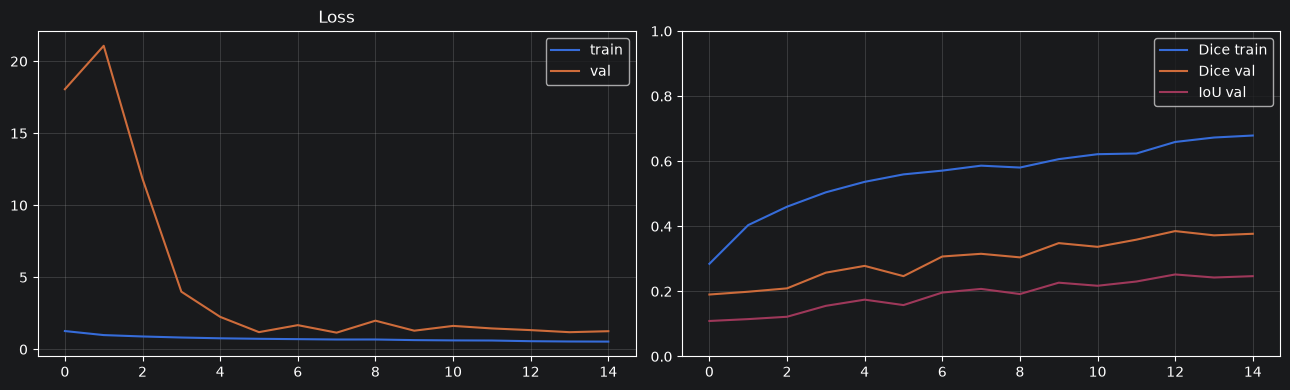

In [5]:
"""
HW1: Улучшение архитектуры U-Net.
Добавлены:
  * Residual-блоки (skip-connection внутри свёрточного блока);
  * Dropout после каждого блока (для регуляризации);
  * Увеличенная глубина (4 пулинг-уровня + bottleneck);
  * base_filters = 16 -> 24.
Ожидаемый эффект: лучшее качество на валидации, меньше переобучения.
"""
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)

IMG_SIZE = 128
TRAIN_SIZE = 150
VAL_SIZE   = 30
EPOCHS     = 15
BATCH      = 8


# ------------------------- Данные -------------------------
def ensure_dataset() -> Path:
    candidates = [Path('./data/total_text'), Path('../data/total_text')]
    for c in candidates:
        if (c / 'Images').exists() and (c / 'Text_Region_Mask').exists():
            return c
    # Попытка скачать через kagglehub (не всегда доступен – при ошибке даём инструкцию)
    try:
        import kagglehub  # noqa
        for slug in ("siddharthm1698/total-text", "pdx97/total-text",
                     "shubhampandey28/total-text"):
            try:
                p = Path(kagglehub.dataset_download(slug))
                if (p / 'Images').exists():
                    print(f'Dataset downloaded to {p}')
                    return p
            except Exception:
                continue
    except Exception:
        pass
    raise RuntimeError(
        "Датасет Total-Text не найден. Поместите Images/ и Text_Region_Mask/ "
        "в ./data/total_text/ или установите kagglehub с зеркалом датасета."
    )


def _load_mask(path, size):
    return (np.array(Image.open(path).convert('L').resize((size, size), Image.NEAREST))
            > 127).astype(np.float32)


def load_split(data_dir: Path, split: str, n: int, size: int, seed: int = 42):
    img_dir = data_dir / 'Images' / split
    msk_dir = data_dir / 'Text_Region_Mask' / split
    pairs = []
    for img in sorted(img_dir.glob('*.jpg')):
        if img.name.startswith('._'):
            continue
        msk = msk_dir / f'{img.stem}.png'
        if msk.exists():
            pairs.append((img, msk))
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(pairs))[:n]
    pairs = [pairs[i] for i in idx]
    X = np.zeros((n, size, size, 3), np.float32)
    Y = np.zeros((n, size, size, 1), np.float32)
    for k, (im, mk) in enumerate(pairs):
        X[k] = np.array(Image.open(im).convert('RGB').resize((size, size),
                                                             Image.BILINEAR), np.float32) / 255.0
        Y[k, ..., 0] = _load_mask(mk, size)
    return X, Y


# ------------------------- Модель -------------------------
def residual_conv_block(x, n, dropout=0.0, name=None):
    shortcut = x
    if shortcut.shape[-1] != n:
        shortcut = layers.Conv2D(n, 1, padding='same')(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    h = layers.Conv2D(n, 3, padding='same', kernel_initializer='he_normal')(x)
    h = layers.BatchNormalization()(h)
    h = layers.Activation('relu')(h)
    h = layers.Conv2D(n, 3, padding='same', kernel_initializer='he_normal')(h)
    h = layers.BatchNormalization()(h)
    h = layers.Add()([h, shortcut])
    h = layers.Activation('relu')(h)
    if dropout > 0:
        h = layers.Dropout(dropout)(h)
    return h


def build_deep_unet(size=IMG_SIZE, base=24, dropout=0.2):
    inp = keras.Input(shape=(size, size, 3))
    e1 = residual_conv_block(inp, base,         dropout*0.25); p1 = layers.MaxPooling2D(2)(e1)
    e2 = residual_conv_block(p1,  base*2,       dropout*0.5 ); p2 = layers.MaxPooling2D(2)(e2)
    e3 = residual_conv_block(p2,  base*4,       dropout*0.5 ); p3 = layers.MaxPooling2D(2)(e3)
    e4 = residual_conv_block(p3,  base*8,       dropout      ); p4 = layers.MaxPooling2D(2)(e4)
    b  = residual_conv_block(p4,  base*16,      dropout      )
    u4 = layers.Conv2DTranspose(base*8, 2, strides=2, padding='same')(b)
    u4 = layers.Concatenate()([u4, e4]); d4 = residual_conv_block(u4, base*8, dropout*0.5)
    u3 = layers.Conv2DTranspose(base*4, 2, strides=2, padding='same')(d4)
    u3 = layers.Concatenate()([u3, e3]); d3 = residual_conv_block(u3, base*4, dropout*0.5)
    u2 = layers.Conv2DTranspose(base*2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2]); d2 = residual_conv_block(u2, base*2, dropout*0.25)
    u1 = layers.Conv2DTranspose(base,   2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1]); d1 = residual_conv_block(u1, base)
    out = layers.Conv2D(1, 1, activation='sigmoid')(d1)
    return keras.Model(inp, out, name='DeepResUNet')


# ------------------------- Метрики / лосс -------------------------
def dice_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    den   = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3])
    return tf.reduce_mean((2*inter + 1e-6)/(den + 1e-6))


def iou_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    union = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3]) - inter
    return tf.reduce_mean((inter + 1e-6)/(union + 1e-6))


def dice_loss(y_true, y_pred):
    inter = tf.reduce_sum(y_true*y_pred, [1,2,3])
    den   = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(y_pred, [1,2,3])
    return 1 - tf.reduce_mean((2*inter + 1e-6)/(den + 1e-6))


def combined_loss(y_true, y_pred):
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred)) + dice_loss(y_true, y_pred)


# ------------------------- Main -------------------------
if __name__ == '__main__':
    data_dir = ensure_dataset()
    X_tr, y_tr = load_split(data_dir, 'Train', TRAIN_SIZE, IMG_SIZE, SEED)
    X_va, y_va = load_split(data_dir, 'Test',  VAL_SIZE,   IMG_SIZE, SEED)
    print(f'Train: {X_tr.shape} / Val: {X_va.shape}, доля текста: {y_tr.mean():.2%}')

    model = build_deep_unet()
    model.summary()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=combined_loss,
                  metrics=[dice_metric, iou_metric])

    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                     epochs=EPOCHS, batch_size=BATCH, verbose=2)
    print(f'\nВремя: {time.time() - t0:.1f} c')

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(hist.history['loss'],     label='train')
    ax[0].plot(hist.history['val_loss'], label='val')
    ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist.history['dice_metric'],     label='Dice train')
    ax[1].plot(hist.history['val_dice_metric'], label='Dice val')
    ax[1].plot(hist.history['val_iou_metric'],  label='IoU val')
    ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig('hw1_curves.png', dpi=120)

    d = model.evaluate(X_va, y_va, verbose=0)
    print(f'Финальные метрики: loss={d[0]:.4f}, Dice={d[1]:.4f}, IoU={d[2]:.4f}')

[ensure_dataset] cwd: C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7
[ensure_dataset] проверил C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text: 1555 .jpg
[ensure_dataset] использую: C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text
[load_split] Train: .jpg = 1255  (пример: C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text\Images\Train\img1001.jpg)
[load_split] Train: найдено PNG (рекурсивно) = 1255
[load_split] Train: пример PNG = C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text\Text_Region_Mask\Train\img1001.png
[load_split] Train: пар image+mask = 1255
[load_split] Test: .jpg = 300  (пример: C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text\Images\Test\img1.jpg)
[load_split] Test: найдено PNG (рекурсивно) = 300
[load_split] Test: пример PNG = C:\Users\Svetozar\PycharmProjects\NTMIP\lab_7\data\total_text\Text_Region_Mask\Test\img1.png
[load_split] Test: пар image+mask = 300
Train: (150, 128, 128, 3), Val: (30, 128, 128, 3),

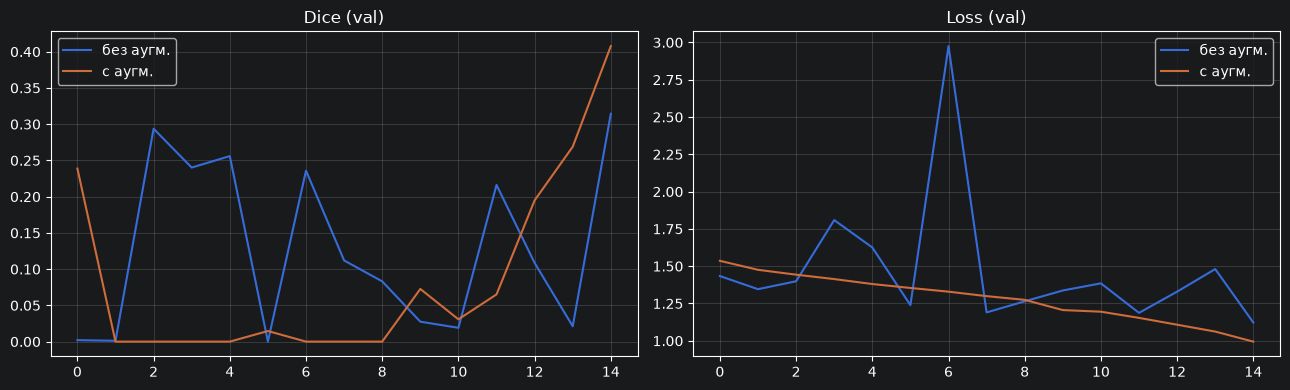

In [6]:
"""
HW2 (исправленная версия): Аугментация через tf.data.
Изменения:
  * ensure_dataset() перебирает больше кандидатов (cwd, родитель cwd, директория скрипта),
    проверяет наличие реальных .jpg и печатает диагностику;
  * load_split() использует rglob — работает и при вложенной структуре папок;
  * печатает, сколько найдено .jpg и .png, какой пример первого файла;
  * бросает понятную ошибку, если пар нет;
  * make_dataset() защищён от пустого входа.
"""
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
import warnings
warnings.filterwarnings('ignore', message='.*NumPy version.*')
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
IMG_SIZE = 128
TRAIN_SIZE, VAL_SIZE = 150, 30
EPOCHS, BATCH = 15, 8


# ------------------------- Поиск данных -------------------------
def ensure_dataset() -> Path:
    """Ищет папку с Images/ и Text_Region_Mask/, где есть хотя бы один .jpg."""
    here = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
    candidates = [
        Path.cwd() / 'data' / 'total_text',
        Path.cwd().parent / 'data' / 'total_text',
        Path.cwd() / 'total_text',
        Path.cwd().parent / 'total_text',
        here / 'data' / 'total_text',
        here.parent / 'data' / 'total_text',
        here / 'total_text',
    ]

    print('[ensure_dataset] cwd:', Path.cwd())
    seen = set()
    for c in candidates:
        try:
            key = c.resolve()
        except Exception:
            key = c
        if key in seen:
            continue
        seen.add(key)
        has_dirs = (c / 'Images').is_dir() and (c / 'Text_Region_Mask').is_dir()
        if not has_dirs:
            continue
        n_jpg = sum(1 for _ in (c / 'Images').rglob('*.jpg'))
        print(f'[ensure_dataset] проверил {c}: {n_jpg} .jpg')
        if n_jpg > 0:
            print(f'[ensure_dataset] использую: {c}')
            return c

    print('\n[ensure_dataset] Итог: подходящая папка не найдена. Кандидаты:')
    for c in candidates:
        print(f'  exists={c.exists():5s}  {c}')
    raise RuntimeError(
        "Не найден датасет Total-Text. Убедитесь, что путь "
        "'./data/total_text/' содержит подпапки 'Images/' и 'Text_Region_Mask/' "
        "и файлы .jpg внутри 'Images/Train' и 'Images/Test'. "
        "Если вы запускаете Jupyter из другого каталога — либо запустите его "
        "из корня проекта NTMIP, либо укажите путь явно через переменную окружения "
        "TOTAL_TEXT_DIR."
    )


def _mask_to_float(p, size):
    return (np.array(Image.open(p).convert('L').resize((size, size), Image.NEAREST))
            > 127).astype(np.float32)


def load_split(root: Path, split: str, n: int, size: int, seed: int = 42):
    img_dir = root / 'Images' / split
    msk_dir = root / 'Text_Region_Mask' / split

    jpgs = [p for p in img_dir.rglob('*.jpg') if not p.name.startswith('._')]
    print(f'[load_split] {split}: .jpg = {len(jpgs)}  (пример: {jpgs[0] if jpgs else "—"})')

    # 1) Сначала ищем PNG в подпапке своего split'а
    all_pngs = list(msk_dir.rglob('*.png')) if msk_dir.exists() else []
    # 2) Если пусто — ищем во всей Text_Region_Mask (на случай другой структуры)
    if not all_pngs:
        all_pngs = list((root / 'Text_Region_Mask').rglob('*.png'))
    # 3) Если всё ещё пусто — ищем вообще во всём root (совсем крайний случай)
    if not all_pngs:
        all_pngs = list(root.rglob('*.png'))

    print(f'[load_split] {split}: найдено PNG (рекурсивно) = {len(all_pngs)}')
    if all_pngs:
        print(f'[load_split] {split}: пример PNG = {all_pngs[0]}')

    pairs = []
    for img in sorted(jpgs):
        # Ищем PNG, в имени которого встречается stem картинки
        # (img1001.jpg -> img1001.png или gt_img1001.png или 1001.png)
        matches = [p for p in all_pngs if img.stem in p.stem]
        if matches:
            pairs.append((img, matches[0]))

    print(f'[load_split] {split}: пар image+mask = {len(pairs)}')
    if not pairs:
        raise RuntimeError(
            f'В папке {split} не найдено ни одной пары image+mask.\n'
            f'  Изображений .jpg: {len(jpgs)}\n'
            f'  PNG найдено рекурсивно: {len(all_pngs)}\n'
            f'  Пример .jpg: {jpgs[0] if jpgs else "—"}\n'
            f'  Пример .png: {all_pngs[0] if all_pngs else "—"}\n'
            'Проверьте, что в именах PNG присутствует имя изображения без расширения '
            '(img1001.jpg <-> img1001.png).'
        )

    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(pairs))[:min(n, len(pairs))]
    pairs = [pairs[i] for i in idx]

    X = np.zeros((len(pairs), size, size, 3), np.float32)
    Y = np.zeros((len(pairs), size, size, 1), np.float32)
    for k, (im, mk) in enumerate(pairs):
        X[k] = np.array(Image.open(im).convert('RGB').resize((size, size),
                                                             Image.BILINEAR), np.float32) / 255.0
        Y[k, ..., 0] = _mask_to_float(mk, size)
    return X, Y


# ------------------------- Аугментация -------------------------
def augment(x, y):
    x = np.asarray(x, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)

    if np.random.rand() < 0.5:
        x = np.ascontiguousarray(np.flip(x, axis=1))
        y = np.ascontiguousarray(np.flip(y, axis=1))

    angle = float(np.random.uniform(-5.0, 5.0))
    if abs(angle) > 0.1:
        pil_x = Image.fromarray((x * 255).astype(np.uint8)).rotate(
            angle, resample=Image.BILINEAR, expand=False)
        x = np.asarray(pil_x, dtype=np.float32) / 255.0

        pil_y = Image.fromarray((y[..., 0] * 255).astype(np.uint8)).rotate(
            angle, resample=Image.NEAREST, expand=False, fillcolor=0)
        y = np.asarray(pil_y, dtype=np.float32)[..., None] / 255.0
        y = (y > 0.5).astype(np.float32)

    x = x + np.float32(np.random.uniform(-0.1, 0.1))
    contrast = np.float32(np.random.uniform(0.9, 1.1))
    mean = x.mean()
    x = (x - mean) * contrast + mean
    x = np.clip(x, 0.0, 1.0).astype(np.float32)
    return x, y


def make_dataset(X, Y, batch=BATCH, shuffle=True, augment_data=False, repeat=True):
    if len(X) == 0:
        raise ValueError('Пустой датасет — проверьте загрузку данных.')
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32)),
                num_parallel_calls=tf.data.AUTOTUNE)
    if augment_data:
        ds = ds.map(lambda x, y: tuple(tf.numpy_function(
            augment, [x, y], [tf.float32, tf.float32])),
            num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (tf.ensure_shape(x, (IMG_SIZE, IMG_SIZE, 3)),
                                  tf.ensure_shape(y, (IMG_SIZE, IMG_SIZE, 1))))
    ds = ds.batch(batch).prefetch(tf.data.AUTOTUNE)
    if repeat:
        ds = ds.repeat()
    return ds


# ------------------------- Модель / метрики -------------------------
def double_conv(x, n):
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    return x


def build_unet(base=16, size=IMG_SIZE):
    inp = keras.Input((size, size, 3))
    e1 = double_conv(inp, base);    p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv(p1, base * 2); p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv(p2, base * 4); p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv(p3, base * 8)
    u3 = layers.Conv2DTranspose(base * 4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3]); d3 = double_conv(u3, base * 4)
    u2 = layers.Conv2DTranspose(base * 2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2]); d2 = double_conv(u2, base * 2)
    u1 = layers.Conv2DTranspose(base, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1]); d1 = double_conv(u1, base)
    return keras.Model(inp, layers.Conv2D(1, 1, activation='sigmoid')(d1))


def dice_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true * yp, [1, 2, 3])
    den = tf.reduce_sum(y_true, [1, 2, 3]) + tf.reduce_sum(yp, [1, 2, 3])
    return tf.reduce_mean((2 * inter + 1e-6) / (den + 1e-6))


def iou_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true * yp, [1, 2, 3])
    union = tf.reduce_sum(y_true, [1, 2, 3]) + tf.reduce_sum(yp, [1, 2, 3]) - inter
    return tf.reduce_mean((inter + 1e-6) / (union + 1e-6))


def dice_loss(y_true, y_pred):
    inter = tf.reduce_sum(y_true * y_pred, [1, 2, 3])
    den = tf.reduce_sum(y_true, [1, 2, 3]) + tf.reduce_sum(y_pred, [1, 2, 3])
    return 1 - tf.reduce_mean((2 * inter + 1e-6) / (den + 1e-6))


def combined_loss(y_true, y_pred):
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred)) + dice_loss(y_true, y_pred)


# ------------------------- Main -------------------------
if __name__ == '__main__':
    env = os.environ.get('TOTAL_TEXT_DIR')
    root = Path(env) if env else ensure_dataset()

    X_tr, y_tr = load_split(root, 'Train', TRAIN_SIZE, IMG_SIZE, SEED)
    X_va, y_va = load_split(root, 'Test', VAL_SIZE, IMG_SIZE, SEED)
    print(f'Train: {X_tr.shape}, Val: {X_va.shape}, доля текста: {y_tr.mean():.2%}')

    assert X_tr.shape[0] > 0 and X_va.shape[0] > 0, 'Пустые выборки — данные не загрузились.'
    steps_tr = max(1, len(X_tr) // BATCH)

    def train_model(use_aug):
        model = build_unet()
        model.compile(keras.optimizers.Adam(1e-3),
                      loss=combined_loss,
                      metrics=[dice_metric, iou_metric])
        ds_tr = make_dataset(X_tr, y_tr, shuffle=True, augment_data=use_aug, repeat=True)
        ds_va = make_dataset(X_va, y_va, shuffle=False, augment_data=False, repeat=False)
        t0 = time.time()
        hist = model.fit(ds_tr, validation_data=ds_va,
                         epochs=EPOCHS, steps_per_epoch=steps_tr,
                         shuffle=False, verbose=2)
        d = model.evaluate(ds_va, verbose=0)
        return model, hist, d, time.time() - t0

    print('\n=== Без аугментации ===')
    m0, h0, d0, t0 = train_model(False)
    print(f'Dice={d0[1]:.4f}  IoU={d0[2]:.4f}  ({t0:.1f} c)')

    print('\n=== С аугментацией ===')
    m1, h1, d1, t1 = train_model(True)
    print(f'Dice={d1[1]:.4f}  IoU={d1[2]:.4f}  ({t1:.1f} c)')

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h0.history['val_dice_metric'], label='без аугм.')
    ax[0].plot(h1.history['val_dice_metric'], label='с аугм.')
    ax[0].set_title('Dice (val)'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h0.history['val_loss'], label='без аугм.')
    ax[1].plot(h1.history['val_loss'], label='с аугм.')
    ax[1].set_title('Loss (val)'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig('hw2_compare.png', dpi=120)
    print('\nСохранено: hw2_compare.png')

Доля текста в масках: 10.13%

--- BCE+Dice (baseline) ---
Dice=0.2242  IoU=0.1441

--- Focal (a=.25, g=2) ---
Dice=0.0326  IoU=0.0205

--- Tversky (a=.3, b=.7) ---
Dice=0.3530  IoU=0.2268

--- Combo (BCE+Dice+Focal) ---
Dice=0.0996  IoU=0.0587

=== Итог ===
BCE+Dice (baseline)            Dice=0.2242  IoU=0.1441
Focal (a=.25, g=2)             Dice=0.0326  IoU=0.0205
Tversky (a=.3, b=.7)           Dice=0.3530  IoU=0.2268
Combo (BCE+Dice+Focal)         Dice=0.0996  IoU=0.0587


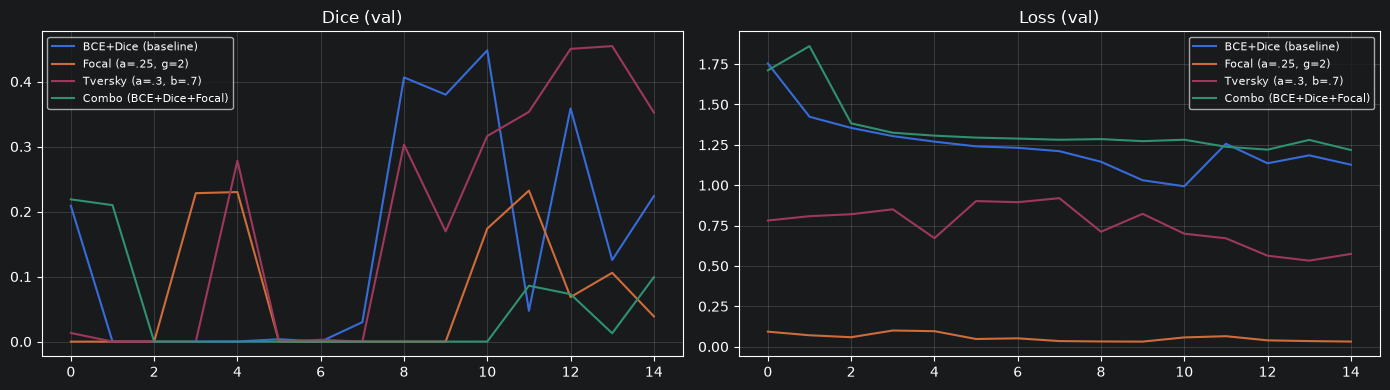

In [7]:
"""
HW3: Сравнение функций потерь при сильном дисбалансе классов.
Реализованы:
  * BCE + Dice (baseline из ноутбука);
  * Focal Loss (alpha=0.25, gamma=2);
  * Tversky Loss (alpha=0.3, beta=0.7 — штраф за пропуски текста);
  * Combo Loss = BCE + Dice + Focal.
Обучаем одну и ту же модель для каждой функции потерь и сравниваем Dice/IoU.
"""
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)
IMG_SIZE = 128; TRAIN_SIZE, VAL_SIZE = 150, 30
EPOCHS, BATCH = 15, 8


def ensure_dataset() -> Path:
    for c in (Path('./data/total_text'), Path('../data/total_text')):
        if (c / 'Images').exists() and (c / 'Text_Region_Mask').exists():
            return c
    raise RuntimeError("Датасет не найден в ./data/total_text.")


def _m(p, s):
    return (np.array(Image.open(p).convert('L').resize((s, s), Image.NEAREST))
            > 127).astype(np.float32)


def load_split(root, split, n, size, seed=42):
    ids = [p for p in sorted((root/'Images'/split).glob('*.jpg'))
           if not p.name.startswith('._')]
    pairs = [(p, root/'Text_Region_Mask'/split/f'{p.stem}.png') for p in ids]
    pairs = [p for p in pairs if p[1].exists()]
    rng = np.random.default_rng(seed)
    pairs = [pairs[i] for i in rng.permutation(len(pairs))[:n]]
    X = np.zeros((len(pairs), size, size, 3), np.float32)
    Y = np.zeros((len(pairs), size, size, 1), np.float32)
    for k, (im, mk) in enumerate(pairs):
        X[k] = np.array(Image.open(im).convert('RGB').resize((size, size),
                                                             Image.BILINEAR), np.float32)/255.
        Y[k, ..., 0] = _m(mk, size)
    return X, Y


# --------------------- Потери ---------------------
EPS = 1e-6


def dice_loss(y_true, y_pred):
    inter = tf.reduce_sum(y_true*y_pred, [1,2,3])
    den = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(y_pred, [1,2,3])
    return 1 - tf.reduce_mean((2*inter + EPS)/(den + EPS))


def bce_loss(y_true, y_pred):
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred))


def focal_loss(alpha=0.25, gamma=2.0):
    def _loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        bce = -y_true*tf.math.log(y_pred) - (1-y_true)*tf.math.log(1-y_pred)
        pt = tf.where(tf.equal(y_true, 1.0), y_pred, 1 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1.0), alpha, 1 - alpha)
        return tf.reduce_mean(alpha_t * (1 - pt) ** gamma * bce)
    return _loss


def tversky_loss(alpha=0.3, beta=0.7):
    def _loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)
        tp = tf.reduce_sum(y_true*y_pred, [1,2,3])
        fp = tf.reduce_sum((1-y_true)*y_pred, [1,2,3])
        fn = tf.reduce_sum(y_true*(1-y_pred), [1,2,3])
        return 1 - tf.reduce_mean((tp + EPS)/(tp + alpha*fp + beta*fn + EPS))
    return _loss


def combo_loss(y_true, y_pred):
    return bce_loss(y_true, y_pred) + dice_loss(y_true, y_pred) + focal_loss()(y_true, y_pred)


# --------------------- Модель ---------------------
def double_conv(x, n):
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    return x


def build_unet(base=16, size=IMG_SIZE):
    inp = keras.Input((size, size, 3))
    e1 = double_conv(inp, base); p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv(p1, base*2); p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv(p2, base*4); p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv(p3, base*8)
    u3 = layers.Conv2DTranspose(base*4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3]); d3 = double_conv(u3, base*4)
    u2 = layers.Conv2DTranspose(base*2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2]); d2 = double_conv(u2, base*2)
    u1 = layers.Conv2DTranspose(base, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1]); d1 = double_conv(u1, base)
    return keras.Model(inp, layers.Conv2D(1, 1, activation='sigmoid')(d1))


def dice_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    den = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3])
    return tf.reduce_mean((2*inter+EPS)/(den+EPS))


def iou_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    union = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3]) - inter
    return tf.reduce_mean((inter+EPS)/(union+EPS))


# --------------------- Main ---------------------
if __name__ == '__main__':
    root = ensure_dataset()
    X_tr, y_tr = load_split(root, 'Train', TRAIN_SIZE, IMG_SIZE, SEED)
    X_va, y_va = load_split(root, 'Test',  VAL_SIZE,   IMG_SIZE, SEED)
    print(f'Доля текста в масках: {y_tr.mean():.2%}')

    variants = {
        'BCE+Dice (baseline)':   lambda t, p: bce_loss(t, p) + dice_loss(t, p),
        'Focal (a=.25, g=2)':    focal_loss(0.25, 2.0),
        'Tversky (a=.3, b=.7)':  tversky_loss(0.3, 0.7),
        'Combo (BCE+Dice+Focal)': combo_loss,
    }

    results = {}
    for name, loss_fn in variants.items():
        print(f'\n--- {name} ---')
        m = build_unet()
        m.compile(keras.optimizers.Adam(1e-3), loss=loss_fn,
                  metrics=[dice_metric, iou_metric])
        h = m.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=EPOCHS, batch_size=BATCH, verbose=0)
        d = m.evaluate(X_va, y_va, verbose=0)
        results[name] = (h, d[1], d[2])
        print(f'Dice={d[1]:.4f}  IoU={d[2]:.4f}')

    # Сводный график
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for name, (h, _, _) in results.items():
        ax[0].plot(h.history['val_dice_metric'], label=name)
        ax[1].plot(h.history['val_loss'],        label=name)
    ax[0].set_title('Dice (val)'); ax[1].set_title('Loss (val)')
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
    ax[0].grid(alpha=.3); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig('hw3_losses.png', dpi=120)

    print('\n=== Итог ===')
    for n, (_, d, i) in results.items():
        print(f'{n:30s} Dice={d:.4f}  IoU={i:.4f}')

=== Baseline: LR=1e-3 без callbacks ===
Epoch 1/15
19/19 - 12s - 613ms/step - dice_metric: 0.3262 - iou_metric: 0.2180 - loss: 1.1804 - val_dice_metric: 8.9535e-10 - val_iou_metric: 8.9535e-10 - val_loss: 1.4345
Epoch 2/15
19/19 - 3s - 176ms/step - dice_metric: 0.4069 - iou_metric: 0.2878 - loss: 1.0376 - val_dice_metric: 8.9535e-10 - val_iou_metric: 8.9535e-10 - val_loss: 1.3265
Epoch 3/15
19/19 - 3s - 162ms/step - dice_metric: 0.4298 - iou_metric: 0.3104 - loss: 0.9720 - val_dice_metric: 8.9535e-10 - val_iou_metric: 8.9535e-10 - val_loss: 1.2733
Epoch 4/15
19/19 - 3s - 159ms/step - dice_metric: 0.4718 - iou_metric: 0.3456 - loss: 0.9174 - val_dice_metric: 8.9535e-10 - val_iou_metric: 8.9535e-10 - val_loss: 1.2540
Epoch 5/15
19/19 - 3s - 153ms/step - dice_metric: 0.4992 - iou_metric: 0.3694 - loss: 0.8620 - val_dice_metric: 0.2705 - val_iou_metric: 0.1629 - val_loss: 1.5400
Epoch 6/15
19/19 - 3s - 152ms/step - dice_metric: 0.5348 - iou_metric: 0.4013 - loss: 0.8120 - val_dice_metric: 

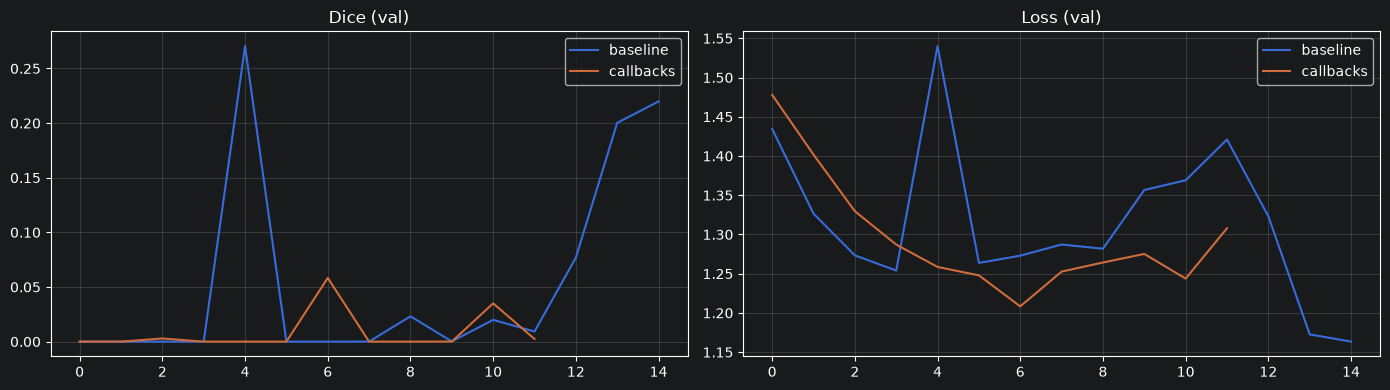

In [8]:
"""
HW4: Регуляризация обучения.
Добавлены:
  * ReduceLROnPlateau — снижение LR при плато val_loss;
  * EarlyStopping — остановка при отсутствии улучшения (patience=5);
  * ModelCheckpoint — сохранение лучшей модели по val_dice.
Сравниваем с фиксированным LR=1e-3 (как в ноутбуке).
"""
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)
IMG_SIZE = 128; TRAIN_SIZE, VAL_SIZE = 150, 30
MAX_EPOCHS, BATCH = 30, 8   # увеличено — EarlyStopping остановит сам


def ensure_dataset() -> Path:
    for c in (Path('./data/total_text'), Path('../data/total_text')):
        if (c / 'Images').exists() and (c / 'Text_Region_Mask').exists():
            return c
    raise RuntimeError("Датасет не найден в ./data/total_text.")


def _m(p, s):
    return (np.array(Image.open(p).convert('L').resize((s, s), Image.NEAREST))
            > 127).astype(np.float32)


def load_split(root, split, n, size, seed=42):
    ids = [p for p in sorted((root/'Images'/split).glob('*.jpg'))
           if not p.name.startswith('._')]
    pairs = [(p, root/'Text_Region_Mask'/split/f'{p.stem}.png') for p in ids]
    pairs = [p for p in pairs if p[1].exists()]
    rng = np.random.default_rng(seed)
    pairs = [pairs[i] for i in rng.permutation(len(pairs))[:n]]
    X = np.zeros((len(pairs), size, size, 3), np.float32)
    Y = np.zeros((len(pairs), size, size, 1), np.float32)
    for k, (im, mk) in enumerate(pairs):
        X[k] = np.array(Image.open(im).convert('RGB').resize((size, size),
                                                             Image.BILINEAR), np.float32)/255.
        Y[k, ..., 0] = _m(mk, size)
    return X, Y


def double_conv(x, n):
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    return x


def build_unet(base=16, size=IMG_SIZE):
    inp = keras.Input((size, size, 3))
    e1 = double_conv(inp, base); p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv(p1, base*2); p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv(p2, base*4); p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv(p3, base*8)
    u3 = layers.Conv2DTranspose(base*4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3]); d3 = double_conv(u3, base*4)
    u2 = layers.Conv2DTranspose(base*2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2]); d2 = double_conv(u2, base*2)
    u1 = layers.Conv2DTranspose(base, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1]); d1 = double_conv(u1, base)
    return keras.Model(inp, layers.Conv2D(1, 1, activation='sigmoid')(d1))


def dice_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    den = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3])
    return tf.reduce_mean((2*inter+1e-6)/(den+1e-6))


def iou_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    union = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3]) - inter
    return tf.reduce_mean((inter+1e-6)/(union+1e-6))


def dice_loss(y_true, y_pred):
    inter = tf.reduce_sum(y_true*y_pred, [1,2,3])
    den = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(y_pred, [1,2,3])
    return 1 - tf.reduce_mean((2*inter+1e-6)/(den+1e-6))


def combined_loss(y_true, y_pred):
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred)) + dice_loss(y_true, y_pred)


if __name__ == '__main__':
    root = ensure_dataset()
    X_tr, y_tr = load_split(root, 'Train', TRAIN_SIZE, IMG_SIZE, SEED)
    X_va, y_va = load_split(root, 'Test',  VAL_SIZE,   IMG_SIZE, SEED)

    # ---------- baseline ----------
    print('=== Baseline: LR=1e-3 без callbacks ===')
    m_base = build_unet()
    m_base.compile(keras.optimizers.Adam(1e-3), combined_loss,
                   metrics=[dice_metric, iou_metric])
    h_base = m_base.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                        epochs=15, batch_size=BATCH, verbose=2)
    print(f'Baseline Dice: {h_base.history["val_dice_metric"][-1]:.4f}')

    # ---------- с callbacks ----------
    print('\n=== С ReduceLROnPlateau + EarlyStopping + Checkpoint ===')
    m = build_unet()
    m.compile(keras.optimizers.Adam(1e-3), combined_loss,
              metrics=[dice_metric, iou_metric])

    cb = [
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
        keras.callbacks.EarlyStopping(
            monitor='val_dice_metric', mode='max', patience=5,
            restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(
            'hw4_best_unet.keras', monitor='val_dice_metric', mode='max',
            save_best_only=True, verbose=1),
    ]
    h = m.fit(X_tr, y_tr, validation_data=(X_va, y_va),
              epochs=MAX_EPOCHS, batch_size=BATCH, verbose=2, callbacks=cb)

    # Графики
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(h_base.history['val_dice_metric'], label='baseline')
    ax[0].plot(h.history['val_dice_metric'], label='callbacks')
    ax[0].set_title('Dice (val)'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h_base.history['val_loss'], label='baseline')
    ax[1].plot(h.history['val_loss'], label='callbacks')
    ax[1].set_title('Loss (val)'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig('hw4_callbacks.png', dpi=120)

    print(f'\nЛучшая модель сохранена в hw4_best_unet.keras')

=== Обучение (15 эпох) ===
Epoch 1/15
19/19 - 8s - 402ms/step - dice_metric: 0.2623 - loss: 1.4650 - val_dice_metric: 0.2168 - val_loss: 1.7114
Epoch 2/15
19/19 - 2s - 129ms/step - dice_metric: 0.3114 - loss: 1.2578 - val_dice_metric: 8.9535e-10 - val_loss: 1.4315
Epoch 3/15
19/19 - 3s - 133ms/step - dice_metric: 0.3472 - loss: 1.1896 - val_dice_metric: 8.9535e-10 - val_loss: 1.3732
Epoch 4/15
19/19 - 3s - 134ms/step - dice_metric: 0.4015 - loss: 1.1214 - val_dice_metric: 8.9535e-10 - val_loss: 1.3326
Epoch 5/15
19/19 - 3s - 140ms/step - dice_metric: 0.4526 - loss: 1.0651 - val_dice_metric: 8.9535e-10 - val_loss: 1.2987
Epoch 6/15
19/19 - 3s - 140ms/step - dice_metric: 0.4821 - loss: 1.0163 - val_dice_metric: 8.9535e-10 - val_loss: 1.2631
Epoch 7/15
19/19 - 3s - 137ms/step - dice_metric: 0.5073 - loss: 0.9688 - val_dice_metric: 8.9535e-10 - val_loss: 1.2420
Epoch 8/15
19/19 - 3s - 139ms/step - dice_metric: 0.5449 - loss: 0.9132 - val_dice_metric: 8.9535e-10 - val_loss: 1.2294
Epoch 9/1

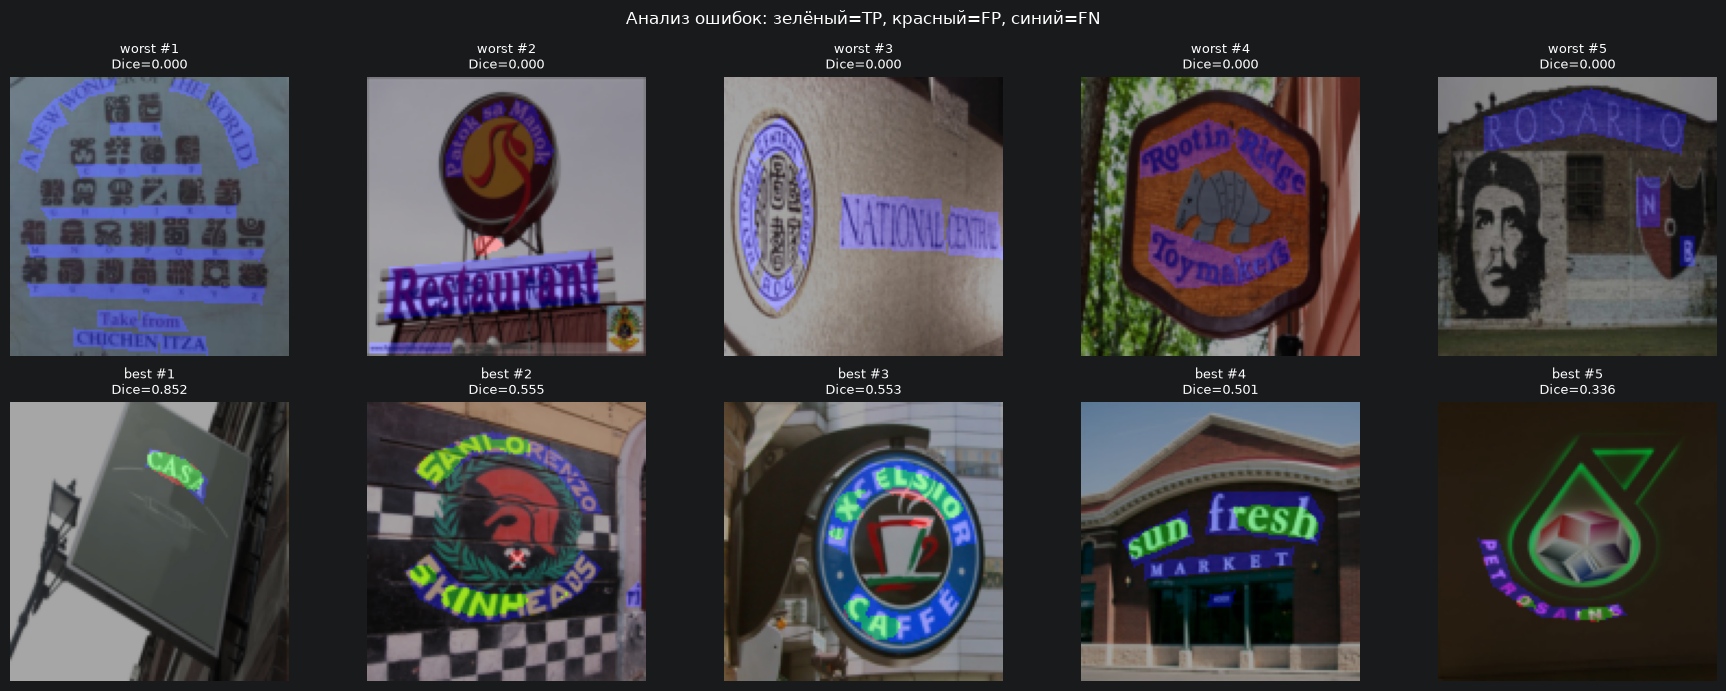

In [9]:
"""
HW5: Улучшение инференса.
  * Test-Time Augmentation (TTA): усреднение предсказаний для исходного
    изображения и его горизонтального отражения;
  * Подбор оптимального порога бинаризации по валидации (максимизация Dice);
  * Per-image анализ: таблица Dice/IoU по 10 примерам + визуализация лучших
    и худших предсказаний.

Использует модель, обученную в этом скрипте (15 эпох, как в ноутбуке).
"""
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)
IMG_SIZE = 128; TRAIN_SIZE, VAL_SIZE = 150, 30
EPOCHS, BATCH = 15, 8


def ensure_dataset() -> Path:
    for c in (Path('./data/total_text'), Path('../data/total_text')):
        if (c / 'Images').exists() and (c / 'Text_Region_Mask').exists():
            return c
    raise RuntimeError("Датасет не найден в ./data/total_text.")


def _m(p, s):
    return (np.array(Image.open(p).convert('L').resize((s, s), Image.NEAREST))
            > 127).astype(np.float32)


def load_split(root, split, n, size, seed=42):
    ids = [p for p in sorted((root/'Images'/split).glob('*.jpg'))
           if not p.name.startswith('._')]
    pairs = [(p, root/'Text_Region_Mask'/split/f'{p.stem}.png') for p in ids]
    pairs = [p for p in pairs if p[1].exists()]
    rng = np.random.default_rng(seed)
    pairs = [pairs[i] for i in rng.permutation(len(pairs))[:n]]
    X = np.zeros((len(pairs), size, size, 3), np.float32)
    Y = np.zeros((len(pairs), size, size, 1), np.float32)
    for k, (im, mk) in enumerate(pairs):
        X[k] = np.array(Image.open(im).convert('RGB').resize((size, size),
                                                             Image.BILINEAR), np.float32)/255.
        Y[k, ..., 0] = _m(mk, size)
    return X, Y


def double_conv(x, n):
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(n, 3, padding='same')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    return x


def build_unet(base=16, size=IMG_SIZE):
    inp = keras.Input((size, size, 3))
    e1 = double_conv(inp, base); p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv(p1, base*2); p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv(p2, base*4); p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv(p3, base*8)
    u3 = layers.Conv2DTranspose(base*4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3]); d3 = double_conv(u3, base*4)
    u2 = layers.Conv2DTranspose(base*2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2]); d2 = double_conv(u2, base*2)
    u1 = layers.Conv2DTranspose(base, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1]); d1 = double_conv(u1, base)
    return keras.Model(inp, layers.Conv2D(1, 1, activation='sigmoid')(d1))


def dice_loss(y_true, y_pred):
    inter = tf.reduce_sum(y_true*y_pred, [1,2,3])
    den = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(y_pred, [1,2,3])
    return 1 - tf.reduce_mean((2*inter+1e-6)/(den+1e-6))


def combined_loss(y_true, y_pred):
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred)) + dice_loss(y_true, y_pred)


def dice_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    inter = tf.reduce_sum(y_true*yp, [1,2,3])
    den = tf.reduce_sum(y_true, [1,2,3]) + tf.reduce_sum(yp, [1,2,3])
    return tf.reduce_mean((2*inter+1e-6)/(den+1e-6))


# ---------------- TTA и подбор порога ----------------
def predict_with_tta(model, X):
    """Усреднение по исходному изображению и горизонтальному отражению."""
    p1 = model.predict(X, verbose=0)
    X_flip = np.flip(X, axis=2)
    p2 = model.predict(X_flip, verbose=0)
    p2 = np.flip(p2, axis=2)
    return 0.5 * (p1 + p2)


def metrics_at(y_true, y_prob, threshold):
    yp = (y_prob > threshold).astype(np.float32)
    inter = np.sum(y_true*yp, axis=(1, 2, 3))
    den_d = np.sum(y_true, axis=(1, 2, 3)) + np.sum(yp, axis=(1, 2, 3))
    den_i = den_d - inter
    dice = (2*inter + 1e-6) / (den_d + 1e-6)
    iou = (inter + 1e-6) / (den_i + 1e-6)
    return dice.mean(), iou.mean()


def pick_threshold(y_true, y_prob, lo=0.30, hi=0.90, steps=25):
    best_t, best_d = 0.5, -1.0
    for t in np.linspace(lo, hi, steps):
        d, _ = metrics_at(y_true, y_prob, t)
        if d > best_d:
            best_d, best_t = d, t
    return best_t, best_d


# ---------------- Main ----------------
if __name__ == '__main__':
    root = ensure_dataset()
    X_tr, y_tr = load_split(root, 'Train', TRAIN_SIZE, IMG_SIZE, SEED)
    X_va, y_va = load_split(root, 'Test',  VAL_SIZE,   IMG_SIZE, SEED)

    model = build_unet()
    model.compile(keras.optimizers.Adam(1e-3), combined_loss,
                  metrics=[dice_metric])
    print('=== Обучение (15 эпох) ===')
    model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
              epochs=EPOCHS, batch_size=BATCH, verbose=2)

    # 1. Обычное предсказание
    p_plain = model.predict(X_va, verbose=0)
    # 2. TTA
    p_tta = predict_with_tta(model, X_va)

    # 3. Подбор порога для TTA на валидации
    best_t, best_d = pick_threshold(y_va, p_tta)
    print(f'\nОптимальный порог (TTA, val): {best_t:.3f} (Dice={best_d:.4f})')

    # 4. Итоговое сравнение
    print('\n=== Сравнение ===')
    for name, prob in [('Без TTA', p_plain), ('TTA', p_tta)]:
        d05, i05 = metrics_at(y_va, prob, 0.5)
        d_opt, i_opt = metrics_at(y_va, prob, best_t)
        print(f'{name:10s} @0.5: Dice={d05:.4f} IoU={i05:.4f}   '
              f'@opt({best_t:.2f}): Dice={d_opt:.4f} IoU={i_opt:.4f}')

    # 5. Per-image анализ на TTA+opt пороге
    yp = (p_tta > best_t).astype(np.float32)
    inter = np.sum(y_va*yp, axis=(1, 2, 3))
    den_d = np.sum(y_va, axis=(1, 2, 3)) + np.sum(yp, axis=(1, 2, 3))
    dice_per = (2*inter + 1e-6) / (den_d + 1e-6)

    order = np.argsort(dice_per)
    worst, best = order[:5], order[-5:][::-1]
    print('\n=== 5 худших Dice на val ===')
    for i in worst:
        print(f'  image[{i}] Dice={dice_per[i]:.4f}, доля текста={y_va[i].mean():.2%}')
    print('=== 5 лучших Dice на val ===')
    for i in best:
        print(f'  image[{i}] Dice={dice_per[i]:.4f}, доля текста={y_va[i].mean():.2%}')

    # 6. Визуализация
    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    for row, idxs in enumerate([worst[:5], best[:5]]):
        for col, i in enumerate(idxs):
            axes[row, col].imshow(X_va[i])
            # накладываем маску: TP зелёный, FP красный, FN синий
            gt = y_va[i, ..., 0] > 0.5
            pr = yp[i, ..., 0] > 0.5
            overlay = np.zeros((*gt.shape, 3), np.float32)
            overlay[gt & pr]  = [0, 1, 0]
            overlay[~gt & pr] = [1, 0, 0]
            overlay[gt & ~pr] = [0, 0, 1]
            axes[row, col].imshow(overlay, alpha=0.35)
            axes[row, col].set_title(f'{"worst" if row==0 else "best"} #{col+1}\nDice={dice_per[i]:.3f}',
                                     fontsize=9)
            axes[row, col].axis('off')
    plt.suptitle('Анализ ошибок: зелёный=TP, красный=FP, синий=FN', fontsize=12)
    plt.tight_layout(); plt.savefig('hw5_per_image.png', dpi=120)
    print('\nСохранено: hw5_per_image.png')